# Track 01 Workflow: How Much of the Preeclampsia Signal Is Just Delivery Timing?

This notebook follows the [analysis workflow](../3-workflow.md). Sections 1 to 8 are the guided steps, with our decisions filled in. Sections 9 to 13 add the analyses that answer our question.

Run it with **Restart & Run All**. It takes about 15 minutes on a laptop, mostly in Section 10. All figures and tables are saved to `results/`.

## 0. Setup

Works on your own computer and on Google Colab. On Colab this cell downloads the repository and installs PyDESeq2, which takes about a minute.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/openbio-datathon-2026").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git", "/content/openbio-datathon-2026"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydeseq2"], check=True)
    os.chdir("/content/openbio-datathon-2026/track-01/notebooks")

# PyDESeq2 prints harmless overflow warnings for a few genes with extreme counts. It runs its fits in
# separate worker processes, so we silence warnings through the environment (which workers inherit) as well.
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Works from track-01/notebooks or from a submission folder (submissions/<team>/notebooks)
DATA_DIR = next((p for p in [Path("../data"), Path("../../../track-01/data")] if p.exists()), Path("../data"))
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)   # only used for jitter and the random draws in Section 10

# The same color for each group in every figure
COLORS = {"PE": "#eb6834", "preterm_control": "#2a78d6", "term_control": "#1baf7a", "FGR_only": "#b5b4ad"}
LABELS = {"PE": "Preeclampsia", "preterm_control": "Preterm control", "term_control": "Term control", "FGR_only": "Growth restriction only"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.grid": True, "grid.color": "#ebebeb", "axes.axisbelow": True, "legend.frameon": False})

import pydeseq2
print("Setup complete. Data folder:", DATA_DIR.resolve(), "| pydeseq2", pydeseq2.__version__)

Setup complete. Data folder: /Users/dheerdoshi/openbio-datathon-2026/track-01/data | pydeseq2 0.5.4


## 1. Pick a Question

**Our question (starter question 6):** How much of the difference between preeclampsia and control placentas could be explained by *when delivery happened*?

**Why this matters.** Every preeclampsia case in this dataset is early onset and was delivered preterm, between 26 and 34 weeks. A placenta keeps changing as pregnancy goes on, so comparing these cases with placentas delivered at full term (39 weeks) mixes up two things: the disease and the extra weeks of pregnancy. If many "preeclampsia genes" turn out to be "delivered-early genes," conclusions about the disease would be wrong.

**How we answer it.** The study has two kinds of controls without preeclampsia: **preterm controls** (spontaneous preterm births at 30 to 33 weeks, the same window as the cases) and **term controls** (39 weeks). This lets us compare preeclampsia against each control group separately, and the two control groups against each other.

## 2. Load and Check the Data

Loads the count table (genes by samples) and the metadata table (one row per sample), then checks that they fit together.

In [2]:
def load_table(path):
    if not path.exists() or path.stat().st_size == 0:
        print(f"{path.name}: pending release (file is empty for now).")
        return None
    return pd.read_csv(path, index_col=0)

counts = load_table(DATA_DIR / "track01_counts_vt.csv")
metadata = load_table(DATA_DIR / "track01_metadata_vt.csv")

if counts is not None and metadata is not None:
    print(f"Counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples")
    print(f"Metadata: {metadata.shape[0]} samples x {metadata.shape[1]} fields")
    print()
    print("Samples in both tables:      ", len(set(counts.columns) & set(metadata.index)))
    print("Counts are nonnegative:      ", bool((counts.values >= 0).all()))
    print("Counts are whole numbers:    ", bool((counts.values % 1 == 0).all()))
    print("Duplicate genes:             ", int(counts.index.duplicated().sum()))
    print("Duplicate samples:           ", int(counts.columns.duplicated().sum()))
    # Put metadata rows in the same order as the count columns
    metadata = metadata.loc[counts.columns]

Counts: 26,485 genes x 30 samples
Metadata: 30 samples x 20 fields

Samples in both tables:       30
Counts are nonnegative:       True
Counts are whole numbers:     True
Duplicate genes:              0
Duplicate samples:            0


All checks pass. Each sample comes from a different pregnancy, so each one counts once.

Next we label every sample with one of four groups for our question, and we look at when each group delivered. Pregnancies with growth restriction but no preeclampsia ("growth restriction only") are neither cases nor controls here, so they appear in plots but not in any test.

,n,earliest,average,latest
q6_group,,,,
PE,15,26.0,30.2,33.7
preterm_control,5,29.9,31.5,33.0
term_control,5,39.0,39.2,39.4
FGR_only,5,26.7,29.1,30.4


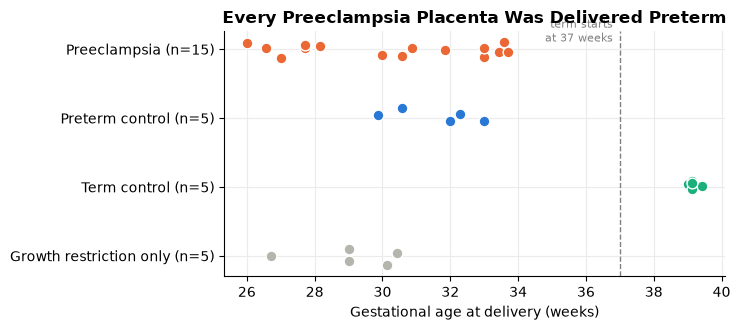

In [3]:
metadata["q6_group"] = np.select(
    [metadata["pe_status"] == "PE", metadata["control_type"] == "preterm_birth", metadata["control_type"] == "term_birth"],
    ["PE", "preterm_control", "term_control"], default="FGR_only")
GROUP_ORDER = ["PE", "preterm_control", "term_control", "FGR_only"]

display(metadata.groupby("q6_group")["ga_delivery_weeks"].agg(n="size", earliest="min", average="mean", latest="max")
        .reindex(GROUP_ORDER).round(1))

# Figure 1: when was each placenta delivered?
fig, ax = plt.subplots(figsize=(7.5, 3.4))
jitter = rng.uniform(-0.15, 0.15, len(metadata))
for i, g in enumerate(GROUP_ORDER):
    sel = (metadata["q6_group"] == g).values
    ax.scatter(metadata.loc[sel, "ga_delivery_weeks"], np.full(sel.sum(), i) + jitter[sel], s=60,
               color=COLORS[g], edgecolor="white", zorder=3)
ax.axvline(37, color="gray", ls="--", lw=1)
ax.text(36.8, -0.45, "term starts\nat 37 weeks", fontsize=8, color="gray", ha="right", va="top")
ax.set_yticks(range(4))
ax.set_yticklabels([f"{LABELS[g]} (n={(metadata['q6_group'] == g).sum()})" for g in GROUP_ORDER])
ax.invert_yaxis()
ax.set_xlabel("Gestational age at delivery (weeks)")
ax.set_title("Every Preeclampsia Placenta Was Delivered Preterm")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig1_delivery_timing.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Preeclampsia placentas were delivered between 26 and 34 weeks (average 30.2). Preterm controls fall in the same window (average 31.5), while term controls sit about 9 weeks later (average 39.2). In a typical study with only term controls, disease and delivery timing would be impossible to separate. The preterm controls are what make our question answerable.

One flagged value matters here: S26's delivery age was published as "38.7" (38 weeks + 7 days). We keep the released value of 39.0 weeks. It is a term control either way.

## 3. Explore the Samples

PCA squeezes each sample's ~16,000 gene measurements into two numbers so we can plot them. Samples close together have similar overall gene activity. We first keep genes with at least 10 reads in at least 5 samples, since almost-silent genes only add noise. We use this same gene list for every test below.

We color the plot two ways: by group, then by delivery week. If timing drove the biggest differences, the delivery-week coloring would show a smooth gradient along the first axis (PC1).

Genes kept: 15,835 of 26,485


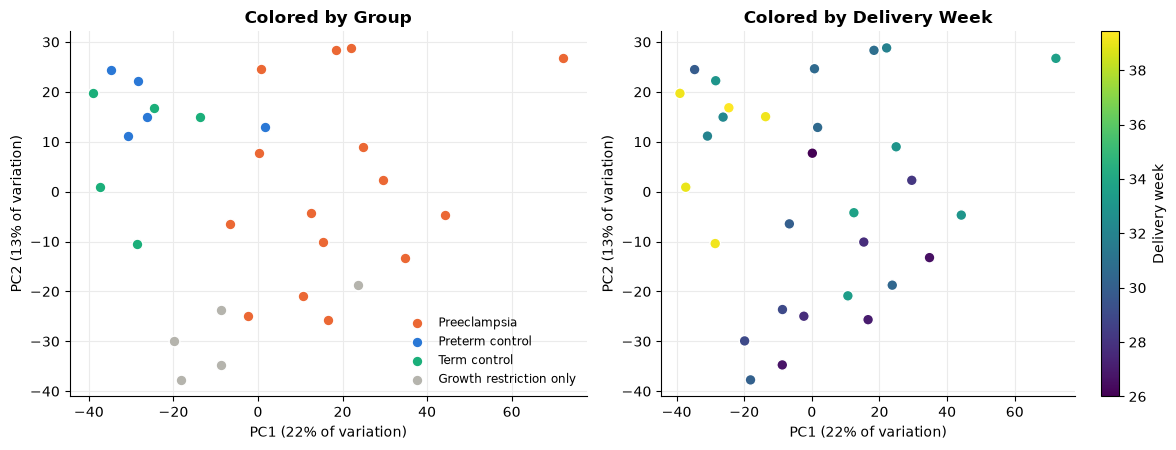

Share of PC1 explained by preeclampsia status: 54%   by delivery week: 12%
Average PC1 position: {'PE': 20.0, 'preterm_control': -24.0, 'term_control': -29.0, 'FGR_only': -6.0}


In [4]:
counts_f = counts.loc[(counts >= 10).sum(axis=1) >= 5]
print(f"Genes kept: {len(counts_f):,} of {len(counts):,}")
log_cpm = np.log2(counts_f.div(counts_f.sum(axis=0), axis=1) * 1e6 + 1)   # depth-adjusted, log scale
pca = PCA(n_components=2)
pcs = pd.DataFrame(pca.fit_transform(log_cpm.T), index=counts_f.columns, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for g in GROUP_ORDER:
    sel = metadata["q6_group"] == g
    axes[0].scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=60, color=COLORS[g], edgecolor="white", label=LABELS[g])
axes[0].legend(fontsize=8.5)
axes[0].set_title("Colored by Group")
pts = axes[1].scatter(pcs["PC1"], pcs["PC2"], c=metadata["ga_delivery_weeks"], cmap="viridis", s=60, edgecolor="white")
fig.colorbar(pts, ax=axes[1], label="Delivery week")
axes[1].set_title("Colored by Delivery Week")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig2_pca.png", dpi=300, bbox_inches="tight")
plt.show()

# How much of PC1 lines up with preeclampsia status vs delivery week? (squared correlation, 0 to 1)
r2_pe = np.corrcoef(pcs["PC1"], metadata["pe_status"] == "PE")[0, 1] ** 2
r2_ga = np.corrcoef(pcs["PC1"], metadata["ga_delivery_weeks"])[0, 1] ** 2
print(f"Share of PC1 explained by preeclampsia status: {r2_pe:.0%}   by delivery week: {r2_ga:.0%}")
print("Average PC1 position:", pcs["PC1"].groupby(metadata["q6_group"]).mean().reindex(GROUP_ORDER).round(0).to_dict())

In [5]:
# Numbers quoted in the text below
ctrl = metadata["q6_group"].isin(["preterm_control", "term_control"])
pe = metadata["q6_group"] == "PE"
r2_ctrl = np.corrcoef(pcs.loc[ctrl, "PC1"], metadata.loc[ctrl, "ga_delivery_weeks"])[0, 1] ** 2
r_pe = np.corrcoef(pcs.loc[pe, "PC1"], metadata.loc[pe, "ga_delivery_weeks"])[0, 1]
print(f"PC1 explains {pca.explained_variance_ratio_[0]:.0%} of total variation")
print(f"Delivery week vs PC1, 10 controls only: {r2_ctrl:.0%} of variation")
print(f"Delivery week vs PC1, 15 PE samples only: r = {r_pe:.2f}")

tot = counts.sum().sort_values()
print(f"S01 reads: {tot['S01_VT']:,.0f} (rank {list(tot.index).index('S01_VT') + 1} lowest of {len(tot)}); median {tot.median():,.0f}")

PC1 explains 22% of total variation
Delivery week vs PC1, 10 controls only: 6% of variation
Delivery week vs PC1, 15 PE samples only: r = 0.36
S01 reads: 6,849,091 (rank 2 lowest of 30); median 11,671,494


**What this shows.** The biggest pattern in the data (PC1, the horizontal axis, about 22% of the total variation) separates preeclampsia from both kinds of control. Preterm and term controls sit together on the left, even though they were delivered about 8 weeks apart: their average PC1 positions differ by only 4.9 units, against 43.2 between preterm controls and preeclampsia. Preeclampsia status accounts for about 54% of the variation along PC1 and delivery week for about 12%. Among the 10 control samples alone, delivery week accounts for only about 6%. Within the preeclampsia samples, PC1 and delivery week are weakly to moderately correlated (r = 0.36, n = 15), so timing may have some influence there. Growth-restriction-only samples fall in between. This describes the largest single pattern, not everything in the data.

One preeclampsia sample (S01) sits far to the right (PC1 = 72, the most extreme of the 30). It lies in the same direction as the other cases, so it looks like an extreme case rather than a broken sample. It has 6.8 million reads, below the median of 11.7 million and the second-lowest of the 30 samples, so low depth could contribute to its position. We keep all 30 samples and check the main result without S01 and S12 in Section 13.

## 4. Choose a Comparison

**Our main comparison:** preeclampsia (15) vs preterm controls (5). The two groups were delivered in similar weeks (preeclampsia averaged 30.2 weeks and preterm controls 31.5, a gap of about 1.3 weeks), so delivery timing is largely matched by design. We check the remaining gap with a covariate in Section 13.

We did not add delivery week as a covariate across all 25 samples. The term controls all sit near 39 weeks, while every preeclampsia sample was delivered by 33.7 weeks. With no cases in the term range, a covariate could not separate the effect of timing from the effect of being a control, so we compare against preterm controls instead.

The other comparisons (preeclampsia vs term controls, and preterm vs term controls) come in Section 9. We chose these three comparisons before looking at any results. Later sensitivity checks (a second fold-change cutoff, a repeated-draw power check, and dropping flagged samples) were added afterward and are labeled as such.

In [6]:
# Our decisions
GROUP_COLUMN = "q6_group"
CASE = "PE"
CONTROL = "preterm_control"
COVARIATES = []

def build_comparison(counts, metadata):
    used = [GROUP_COLUMN] + list(COVARIATES)
    meta = metadata[metadata[GROUP_COLUMN].isin([CASE, CONTROL])][used].copy()
    n_before = len(meta)
    meta = meta.dropna()
    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")
    print(meta[GROUP_COLUMN].value_counts().to_string())
    return counts[meta.index], meta

comp_counts, comp_meta = build_comparison(counts_f, metadata)

q6_group
PE                 15
preterm_control     5


## 5. Run the Test

PyDESeq2 first adjusts for sequencing depth. Then, for every gene, it tests whether the difference between the two groups is larger than the normal sample-to-sample variation within each group. We wrap it in two small functions (fit_deseq and test_contrast) because later sections reuse them with identical settings. Here we run the main comparison, preeclampsia vs preterm controls, with no covariates. This model uses only those 20 samples, and the gene filter from Section 3 (at least 10 reads in at least 5 samples).

In [7]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

INFERENCE = DefaultInference(n_cpus=os.cpu_count())

def fit_deseq(cnts, meta, design):
    dds = DeseqDataSet(counts=cnts.T.astype(int), metadata=meta, design=design, quiet=True, inference=INFERENCE)
    dds.deseq2()
    return dds

def test_contrast(dds, contrast):
    st = DeseqStats(dds, contrast=contrast, quiet=True, inference=INFERENCE)
    st.summary()
    return st.results_df.sort_values("padj")

design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
print("Design:", design)
results = test_contrast(fit_deseq(comp_counts, comp_meta, design), [GROUP_COLUMN, CASE, CONTROL])
results.to_csv(RESULTS_DIR / "de_results.csv")
print(f"Tested {len(results):,} genes. Saved to results/de_results.csv")
display(results.head(10))

Design: ~q6_group
Tested 15,835 genes. Saved to results/de_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
LEPROTL1,741.163767,1.000805,0.088343,11.328640,9.466275e-30,1.440388e-25
NTRK2,256.383815,3.860358,0.454034,8.502362,1.857713e-17,1.413348e-13
AFF3,260.879652,-1.653637,0.198556,-8.328325,8.199401e-17,4.158736e-13
COASY,820.215985,-0.994770,0.122086,-8.148095,3.697031e-16,1.406350e-12
AMD1,3677.103819,1.028512,0.134195,7.664304,1.798039e-14,5.471791e-11
ENG,7529.862816,2.090184,0.286009,7.308099,2.709484e-13,6.871253e-10
FLT1,126519.988711,2.999385,0.415549,7.217877,5.280535e-13,1.147837e-09
CP,162.539974,4.194032,0.582533,7.199645,6.036960e-13,1.148230e-09
HTRA4,9870.028873,2.970925,0.418948,7.091398,1.327643e-12,2.244602e-09


The top genes by adjusted p-value include FLT1 and ENG, two genes with well-documented links to preeclampsia, but ranking by p-value favors precisely measured genes, so we also filter by fold change below.

In [8]:
print(results.loc[["FLT1", "ENG", "LEP", "PAPPA2", "HLA-G"], ["baseMean", "log2FoldChange", "padj"]].round(3))

          baseMean  log2FoldChange   padj
gene                                     
FLT1    126519.989           2.999  0.000
ENG       7529.863           2.090  0.000
LEP      24964.794           5.441  0.000
PAPPA2  142897.366           1.820  0.000
HLA-G      403.509           0.200  0.899


## 6. Read the Results

**Our cutoffs: adjusted p-value below 0.05 and at least a 2-fold change** (`|log2FoldChange| >= 1`).

- `padj < 0.05` is the usual standard. It means we expect about 5% of the genes called significant to be false alarms.
- The 2-fold floor keeps effects large enough to matter biologically. With only 5 controls, small changes are the least trustworthy anyway.

The table under the plot shows how the count shifts with stricter or looser cutoffs.

472 genes pass (283 higher in preeclampsia, 189 lower).


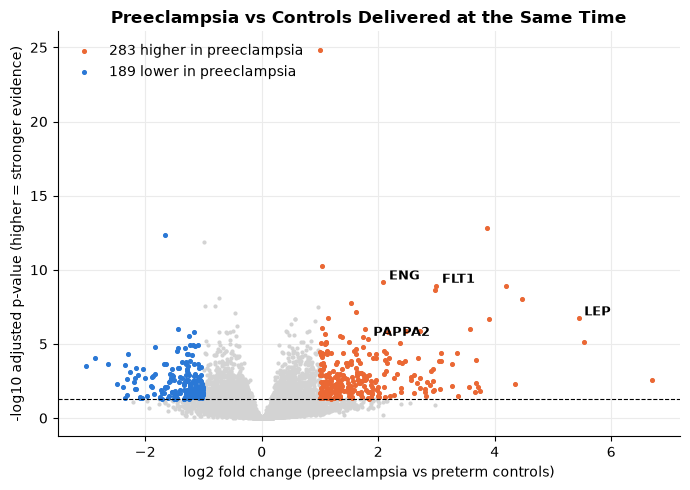

,at least 1.5-fold,at least 2.0-fold,at least 4.0-fold
padj < 0.01,613,293,67
padj < 0.05,1083,472,90
padj < 0.1,1377,564,96


In [9]:
PADJ_CUTOFF = 0.05
LFC_CUTOFF = 1.0

def passing_genes(res, padj=PADJ_CUTOFF, lfc=LFC_CUTOFF):
    return res[(res["padj"] < padj) & (res["log2FoldChange"].abs() >= lfc)]

hits = passing_genes(results)
hits.to_csv(RESULTS_DIR / "passing_genes.csv")
up, down = hits[hits["log2FoldChange"] > 0], hits[hits["log2FoldChange"] < 0]
print(f"{len(hits)} genes pass ({len(up)} higher in preeclampsia, {len(down)} lower).")

fig, ax = plt.subplots(figsize=(7, 5))
nlp = lambda r: -np.log10(r["padj"].clip(lower=1e-300))
ax.scatter(results["log2FoldChange"], nlp(results), s=4, color="lightgray", rasterized=True)
ax.scatter(up["log2FoldChange"], nlp(up), s=7, color=COLORS["PE"], label=f"{len(up)} higher in preeclampsia")
ax.scatter(down["log2FoldChange"], nlp(down), s=7, color=COLORS["preterm_control"], label=f"{len(down)} lower in preeclampsia")
ax.axhline(-np.log10(PADJ_CUTOFF), ls="--", lw=0.8, color="black")
for g in ["FLT1", "LEP", "ENG", "PAPPA2"]:
    ax.annotate(g, (results.loc[g, "log2FoldChange"], nlp(results.loc[[g]]).iloc[0]), fontsize=9, fontweight="bold",
                xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("log2 fold change (preeclampsia vs preterm controls)")
ax.set_ylabel("-log10 adjusted p-value (higher = stronger evidence)")
ax.set_title("Preeclampsia vs Controls Delivered at the Same Time")
ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "volcano.png", dpi=300, bbox_inches="tight")
plt.show()

display(pd.DataFrame({f"at least {2**l:.1f}-fold": {f"padj < {p}": len(passing_genes(results, p, l)) for p in (0.01, 0.05, 0.1)}
                      for l in (0.58, 1, 2)}))

**What this shows.** Against controls delivered in similar weeks, 472 genes differ at least 2-fold at padj < 0.05. Most of them (283) are *higher* in preeclampsia and 189 are lower. Several genes with known links to preeclampsia are among the hits:

- **FLT1** (about 8-fold higher) makes sFlt-1, a protein that blocks blood-vessel growth. Its blood level is part of a clinical test for preeclampsia.
- **ENG** (about 4-fold higher) makes endoglin, another vessel-blocking protein.
- **LEP** (leptin, about 43-fold higher) and **PAPPA2** (about 3.5-fold higher) have been reported to be raised in preeclamptic placentas.

The count depends mostly on the fold-change floor (1,083 genes at 1.5-fold, 472 at 2-fold, 90 at 4-fold) and much less on the p-value cutoff (293 to 564 genes from padj < 0.01 to 0.1).

## 7. Connect Genes to Cell Types

Bulk tissue mixes many cell types. A marker is a gene used mostly by one cell type, so if several markers of one type move together, the tissue may simply contain more or less of that cell type. Here we check which of our passing genes (preeclampsia vs preterm controls) are markers. Only 2 of the 36 markers pass: KIT (a decidual NK marker, higher in preeclampsia) and CGA (a syncytiotrophoblast marker, higher). With only one passing marker in each class, this gives no clear sign of a shift in cell mix. We did not test whether whole marker classes move together, so a modest change in cell mix cannot be ruled out.

In [10]:
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
overlap = markers.merge(hits[["log2FoldChange", "padj"]], left_on="gene_symbol", right_index=True)
display(overlap.sort_values(["cell_class", "log2FoldChange"]) if not overlap.empty else "No passing genes are markers.")

,cell_class,compartment,gene_symbol,log2FoldChange,padj
13,decidual_nk_cell,maternal,KIT,1.778870,9.372956e-07
4,syncytiotrophoblast,fetal,CGA,1.168622,1.358345e-02


Next we looked up five genes in the [Zeisel/Admati gene browser](https://storage.googleapis.com/www_zeisellab/PE_web/pe_web_test_v1.html), a single-cell map of placentas from a different preeclampsia study. We picked genes that tell our story, not just the top of the list:

**FLT1, ENG, PAPPA2, LEP:** well measured and higher in preeclampsia against preterm controls (Section 6).
**HLA-G:** does not differ against preterm controls (padj 0.90). It looks higher in preeclampsia only against term controls (Section 11), which fits timing or tissue mix.

The browser’s significance stars are not explained on the page, and we have not confirmed what they mean, so we do not use them as evidence. We record only which cell types express each gene and how specific the expression is. Browser images are supporting context from other patients, not proof.

In [11]:
browser_lookups = pd.DataFrame([
    {"gene": "FLT1", "cell_types_expressing": "Extravillous trophoblast (highest), other trophoblast, blood-vessel cells",
     "specificity": "a few types",
     "notes": "Bulk: higher in PE against preterm controls. Browser used for cell types only."},
    {"gene": "ENG", "cell_types_expressing": "Endothelial cells (highest), macrophages, some trophoblast",
     "specificity": "broad",
     "notes": "Too widespread to pin to one cell type from bulk data"},
    {"gene": "PAPPA2", "cell_types_expressing": "Extravillous trophoblast, some syncytiotrophoblast",
     "specificity": "trophoblast only",
     "notes": "Bulk: higher in PE against preterm controls"},
    {"gene": "LEP", "cell_types_expressing": "Syncytiotrophoblast (sparse)",
     "specificity": "one type",
     "notes": "Syncytiotrophoblast is poorly captured by single-cell methods, so the signal is faint"},
    {"gene": "HLA-G", "cell_types_expressing": "Extravillous trophoblast only",
     "specificity": "one type",
     "notes": "Classic EVT marker; its bulk difference may reflect timing or tissue mix, not disease"},
])
browser_lookups.to_csv(RESULTS_DIR / "browser_lookups.csv", index=False)
display(browser_lookups)

,gene,cell_types_expressing,specificity,notes
0,FLT1,"Extravillous trophoblast (highest), other trop...",a few types,Bulk: higher in PE against preterm controls. B...
1,ENG,"Endothelial cells (highest), macrophages, some...",broad,Too widespread to pin to one cell type from bu...
2,PAPPA2,"Extravillous trophoblast, some syncytiotrophob...",trophoblast only,Bulk: higher in PE against preterm controls
3,LEP,Syncytiotrophoblast (sparse),one type,Syncytiotrophoblast is poorly captured by sing...
4,HLA-G,Extravillous trophoblast only,one type,Classic EVT marker; its bulk difference may re...


## 8. Optional: Single-Cell Extension

We did not use the pseudobulk files. In the single-cell data, the early-onset comparison has only 3 control donors, too few to measure a timing effect reliably. A cell-type-by-cell-type timing comparison is listed as a next step at the end of the notebook.

---
# Answering Question 6

## 9. Same Disease, Different Controls

If delivery timing were behind the preeclampsia signal, we would expect:

1. **PE vs term controls** (about 9 weeks apart) to show many more differences than **PE vs preterm controls** (same weeks). Both comparisons use 15 cases and 5 controls, so the comparison is fair.
2. **Preterm vs term controls** (no disease, 8 weeks apart) to show many differences of their own.

We fit one model with all three groups, so the three comparisons share the same estimates of noise. We also run the "naive" comparison many studies would start with: PE vs all 10 controls pooled.

In [12]:
cmp_meta = metadata.loc[metadata["q6_group"] != "FGR_only", ["q6_group", "fgr_status", "fetal_sex"]].copy()
cmp_meta["pe_vs_control"] = np.where(cmp_meta["q6_group"] == "PE", "PE", "control")
cmp_counts = counts_f[cmp_meta.index]

dds3 = fit_deseq(cmp_counts, cmp_meta, "~q6_group")
res = {
    "PE vs all controls (naive)": test_contrast(fit_deseq(cmp_counts, cmp_meta, "~pe_vs_control"), ["pe_vs_control", "PE", "control"]),
    "PE vs term controls": test_contrast(dds3, ["q6_group", "PE", "term_control"]),
    "PE vs preterm controls": test_contrast(dds3, ["q6_group", "PE", "preterm_control"]),
    "Preterm vs term controls": test_contrast(dds3, ["q6_group", "preterm_control", "term_control"]),
}
for name, r in res.items():
    r.to_csv(RESULTS_DIR / f"de_{name.split(' (')[0].replace(' ', '_')}.csv")

de_counts = pd.DataFrame({
    "samples": ["15 vs 10", "15 vs 5", "15 vs 5", "5 vs 5"],
    "genes passing": [len(passing_genes(r)) for r in res.values()],
}, index=res.keys())
de_counts.to_csv(RESULTS_DIR / "de_counts_by_comparison.csv")
display(de_counts)

,samples,genes passing
PE vs all controls (naive),15 vs 10,582
PE vs term controls,15 vs 5,532
PE vs preterm controls,15 vs 5,522
Preterm vs term controls,5 vs 5,11


In [13]:
# Counts at both cutoffs
both = pd.DataFrame({f"|log2FC| >= {l}": [len(passing_genes(r, PADJ_CUTOFF, l)) for r in res.values()]
                     for l in (1.0, 0.5)}, index=res.keys())
both.to_csv(RESULTS_DIR / "de_counts_both_cutoffs.csv")
display(both)

# Do the two PE comparisons find the same genes?
a = set(passing_genes(res["PE vs term controls"]).index)
b = set(passing_genes(res["PE vs preterm controls"]).index)
print(f"{len(a & b)} shared | {len(a - b)} only vs term | {len(b - a)} only vs preterm")

,|log2FC| >= 1.0,|log2FC| >= 0.5
PE vs all controls (naive),582,1849
PE vs term controls,532,1348
PE vs preterm controls,522,1458
Preterm vs term controls,11,15


235 shared | 297 only vs term | 287 only vs preterm


**What this shows.** Against term controls and against same-weeks preterm controls, the same number of genes pass (532 each), but only 240 are shared. Preterm and term controls, delivered about 8 weeks apart, differ in 11 genes at 2-fold in this model.

That model shares noise estimates with the preeclampsia group, so it has lower power for this contrast. Section 10 re-tests timing at equal 5-vs-5 sample size. The naive pooled comparison finds 582 genes.

## 10. Is That Just Because 5 vs 5 Is a Small Test?

With only 5 samples per group, a test can miss real differences. To check, we ran two other comparisons of exactly the same size, 20 times each:

- **5 random preeclampsia cases vs the 5 preterm controls.** This shows how many genes a real disease difference produces at this sample size.
- **The 10 controls split into two random groups of 5.** Most splits mix preterm and term controls, so this is a rough noise baseline that includes some timing signal

If timing mattered as much as preeclampsia, the real preterm-vs-term result would look like the first set. If timing barely mattered, it would look like the second.

--- |log2FC| >= 1.0 ---
5 PE vs 5 preterm controls range: 232 - 763
Random splits of controls range:  0 - 17
Preterm vs term controls (real):  86
--- |log2FC| >= 0.5 ---
5 PE vs 5 preterm controls range: 509 - 1971
Random splits of controls range:  0 - 28
Preterm vs term controls (real):  160


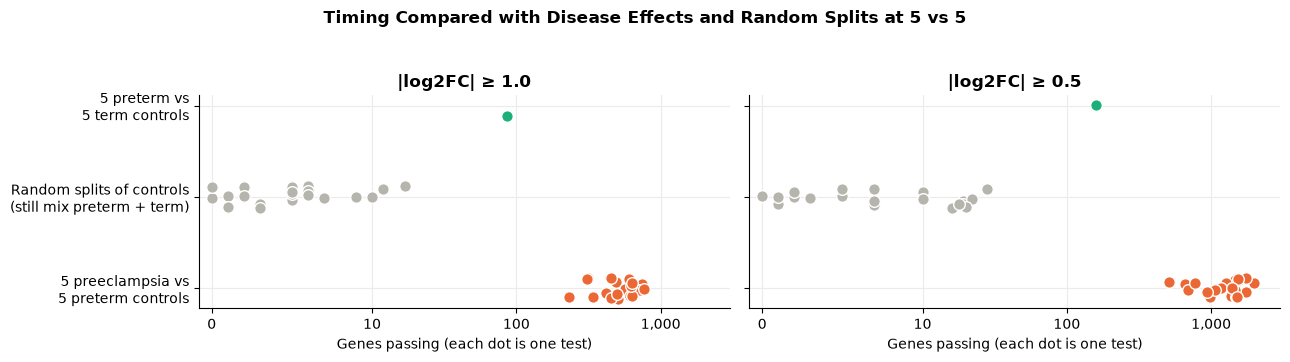

In [14]:
N_DRAWS = 20
LFCS = (1.0, 0.5)
pe_ids = cmp_meta.index[cmp_meta["q6_group"] == "PE"].tolist()
pre_ids = cmp_meta.index[cmp_meta["q6_group"] == "preterm_control"].tolist()
term_ids = cmp_meta.index[cmp_meta["q6_group"] == "term_control"].tolist()

def n_genes_5v5(a_ids, b_ids):
    m = pd.DataFrame({"grp": ["A"] * 5 + ["B"] * 5}, index=list(a_ids) + list(b_ids))
    r = test_contrast(fit_deseq(counts_f[m.index], m, "~grp"), ["grp", "A", "B"])
    return {l: len(passing_genes(r, PADJ_CUTOFF, l)) for l in LFCS}

disease_draws, noise_draws = [], []
for _ in range(N_DRAWS):
    disease_draws.append(n_genes_5v5(rng.choice(pe_ids, 5, replace=False), pre_ids))
    split = list(rng.permutation(pre_ids + term_ids))
    while set(split[:5]) in (set(pre_ids), set(term_ids)):   # skip the real split
        split = list(rng.permutation(pre_ids + term_ids))
    noise_draws.append(n_genes_5v5(split[:5], split[5:]))

timing_actual = n_genes_5v5(pre_ids, term_ids)   # same 5 vs 5 fit as the draws
pd.DataFrame({"disease_lfc1": [d[1.0] for d in disease_draws], "disease_lfc0.5": [d[0.5] for d in disease_draws],
              "mixed_split_lfc1": [d[1.0] for d in noise_draws], "mixed_split_lfc0.5": [d[0.5] for d in noise_draws]}
             ).to_csv(RESULTS_DIR / "power_check.csv", index=False)

for l in LFCS:
    print(f"--- |log2FC| >= {l} ---")
    print("5 PE vs 5 preterm controls range:", min(d[l] for d in disease_draws), "-", max(d[l] for d in disease_draws))
    print("Random splits of controls range: ", min(d[l] for d in noise_draws), "-", max(d[l] for d in noise_draws))
    print("Preterm vs term controls (real): ", timing_actual[l])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, l in zip(axes, LFCS):
    rows = [("5 preeclampsia vs\n5 preterm controls", [d[l] for d in disease_draws], COLORS["PE"]),
            ("Random splits of controls\n(still mix preterm + term)", [d[l] for d in noise_draws], "#b5b4ad"),
            ("5 preterm vs\n5 term controls", [timing_actual[l]], COLORS["term_control"])]
    for i, (lab, vals, c) in enumerate(rows):
        ax.scatter(vals, i + rng.uniform(-0.12, 0.12, len(vals)), s=70, color=c, edgecolor="white", zorder=3)
    ax.set_yticks(range(3)); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
    ax.set_xscale("symlog", linthresh=10); ax.set_xlim(-0.8, 3000)
    ax.set_xticks([0, 10, 100, 1000]); ax.set_xticklabels(["0", "10", "100", "1,000"])
    ax.set_xlabel("Genes passing (each dot is one test)")
    ax.set_title(f"|log2FC| ≥ {l}")
fig.suptitle("Timing Compared with Disease Effects and Random Splits at 5 vs 5", fontweight="bold", y=1.05)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig3_power_check.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows.** Five preeclampsia cases vs five preterm controls give 232 to 763 genes at the 2-fold cutoff (509 to 1,971 at 1.4-fold), so a 5-vs-5 test can detect a real difference. Random splits of the controls give 0 to 17 genes (0 to 28 at 1.4-fold). The real preterm-vs-term comparison gives 86 genes (160 at 1.4-fold): clearly above the random splits, but well below the preeclampsia range.

So timing has a real effect, but it is smaller than the disease effect. Section 9’s count of 11 came from a three-group model with lower power for this contrast, so we use this equal-size number.

## 11. Putting a Number on It

Take every gene that passes for **PE vs term controls**, the comparison most exposed to timing. On the log scale, its difference splits exactly into two parts:

> (PE vs term) = (PE vs preterm) **+** (preterm vs term)
>
> total difference = **disease part** (same delivery weeks) + **timing part** (controls only)

For each gene we ask which part carries it:

- **Holds up against same-time controls:** still significant against preterm controls, in the same direction.
- **Looks driven by timing:** no longer significant against preterm controls, and the timing part makes up at least half of the original difference.
- **Unclear:** neither; the data are too noisy to say.

532 genes differ between preeclampsia and term controls. Of these:
   52%  Holds up against same-time controls
   19%  Unclear
   28%  Looks driven by timing

For the typical gene, the timing part is 30% of the total difference.

Best-measured genes Looks driven by timing:


,total,disease,timing,baseMean
gene,,,,
FN1,2.17,0.74,1.43,126833.35
PSG2,1.00,0.31,0.70,31776.41
TIMP3,1.39,0.39,1.00,17349.15
PRG2,3.00,0.41,2.59,16295.87
SERPINE1,1.36,0.60,0.75,9081.41
AOC1,1.90,0.74,1.16,8627.70
ISM2,1.17,0.13,1.04,4303.37
MUC15,-1.16,-0.49,-0.67,2163.27


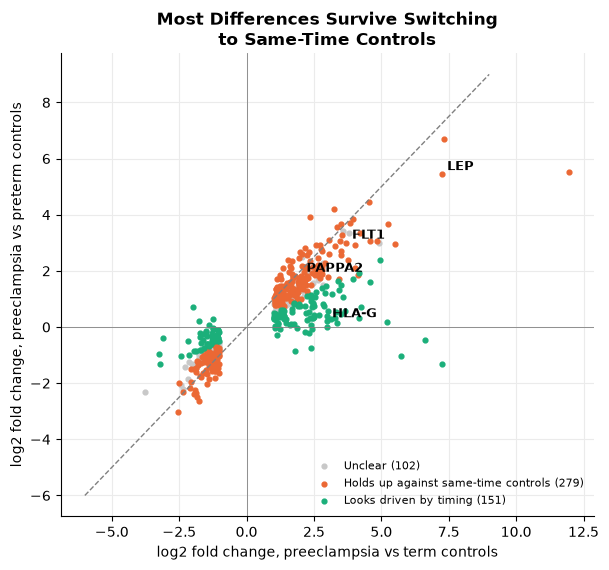

In [15]:
lfc = pd.DataFrame({k: res[k]["log2FoldChange"] for k in ["PE vs term controls", "PE vs preterm controls", "Preterm vs term controls"]})
lfc.columns = ["total", "disease", "timing"]
padj_disease = res["PE vs preterm controls"]["padj"]

term_hits = passing_genes(res["PE vs term controls"]).index
holds = (padj_disease < PADJ_CUTOFF) & (np.sign(lfc["disease"]) == np.sign(lfc["total"]))
timing_share = lfc["timing"] / lfc["total"]
category = pd.Series("Unclear", index=term_hits)
category[holds[term_hits]] = "Holds up against same-time controls"
category[(~holds & (timing_share >= 0.5))[term_hits]] = "Looks driven by timing"
share = category.value_counts(normalize=True)

print(f"{len(term_hits)} genes differ between preeclampsia and term controls. Of these:")
for c in ["Holds up against same-time controls", "Unclear", "Looks driven by timing"]:
    print(f"  {share.get(c, 0):4.0%}  {c}")
print(f"\nFor the typical gene, the timing part is {timing_share[term_hits].median():.0%} of the total difference.")
category.rename("category").to_frame().join(lfc).to_csv(RESULTS_DIR / "pe_vs_term_genes_classified.csv")
print("\nBest-measured genes Looks driven by timing:")
display(lfc.loc[category.index[category == "Looks driven by timing"]]
        .join(res["PE vs term controls"]["baseMean"]).sort_values("baseMean", ascending=False).head(8).round(2))

# Figure: each gene's difference against term controls (x) and against same-time controls (y)
cat_colors = {"Holds up against same-time controls": COLORS["PE"], "Unclear": "#c8c8c8", "Looks driven by timing": COLORS["term_control"]}
fig, ax = plt.subplots(figsize=(6.2, 5.8))
for c in ["Unclear", "Holds up against same-time controls", "Looks driven by timing"]:
    g = category.index[category == c]
    ax.scatter(lfc.loc[g, "total"], lfc.loc[g, "disease"], s=12, color=cat_colors[c], label=f"{c} ({len(g)})")
ax.plot([-6, 9], [-6, 9], color="gray", ls="--", lw=1)
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
for g in ["FLT1", "LEP", "PAPPA2", "HLA-G"]:
    ax.annotate(g, (lfc.loc[g, "total"], lfc.loc[g, "disease"]), fontsize=9, fontweight="bold", xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("log2 fold change, preeclampsia vs term controls")
ax.set_ylabel("log2 fold change, preeclampsia vs preterm controls")
ax.set_title("Most Differences Survive Switching\nto Same-Time Controls")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig4_term_vs_preterm_fold_changes.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
print(category.get("HLA-G"), lfc.loc["HLA-G"].round(2).to_dict())

Looks driven by timing {'total': 2.97, 'disease': 0.2, 'timing': 2.77}


**What this shows.** Of the 532 genes that differ between preeclampsia and term controls:

53% hold up against controls delivered in the same weeks. These include FLT1, LEP and PAPPA2, which show about the same difference against either control group.

28% look driven by timing. Their differences fall toward zero when same-time controls are used (for example HLA-G, FN1, TIMP3, PRG2 and SERPINE1).

18% are unclear.

For the typical gene, timing accounts for about 30% of its difference from term controls. Timing effects are real but smaller than the disease effect: 86 genes differ between preterm and term controls in an equal-size 5-vs-5 test (Section 10). Some timing-driven genes (HLA-G, PRG2) are associated with extravillous trophoblast, so preterm and term samples may contain different amounts of that tissue. This is our speculation, and the classification is approximate.

## 12. Seeing It Sample by Sample

Two genes show the two patterns. Each dot is one placenta, plotted by delivery week.

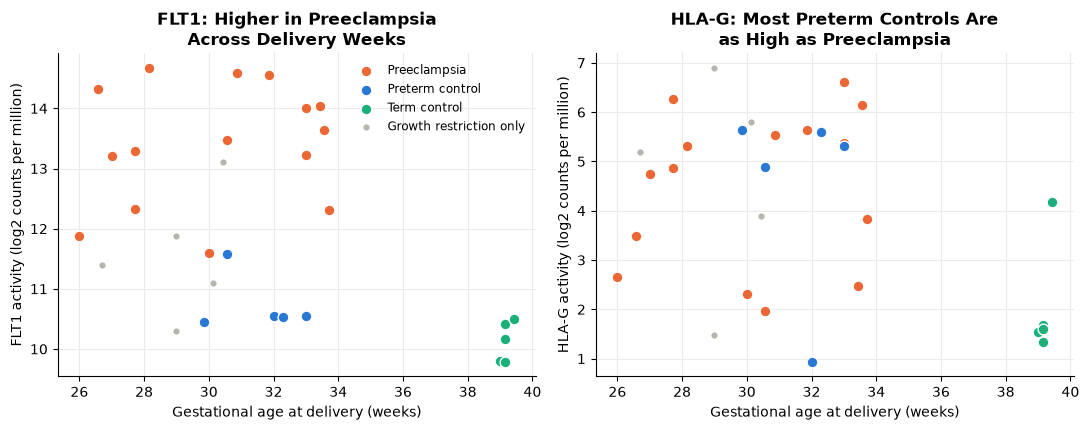

In [17]:
def gene_vs_week(ax, gene, legend=False):
    for g in GROUP_ORDER:
        sel = metadata["q6_group"] == g
        ax.scatter(metadata.loc[sel, "ga_delivery_weeks"], log_cpm.loc[gene, sel], s=60 if g != "FGR_only" else 30,
                   color=COLORS[g], edgecolor="white", label=LABELS[g], zorder=3 if g != "FGR_only" else 2)
    ax.set_xlabel("Gestational age at delivery (weeks)")
    ax.set_ylabel(f"{gene} activity (log2 counts per million)")
    if legend:
        ax.legend(fontsize=8.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
gene_vs_week(axes[0], "FLT1", legend=True)
axes[0].set_title("FLT1: Higher in Preeclampsia\nAcross Delivery Weeks")
gene_vs_week(axes[1], "HLA-G")
axes[1].set_title("HLA-G: Most Preterm Controls Are\nas High as Preeclampsia")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig5_genes_by_delivery_week.png", dpi=300, bbox_inches="tight")
plt.show()

**What this shows**. FLT1 is higher in nearly every preeclampsia placenta than in any control, whether delivered at 26 or 34 weeks. Preterm controls (30 to 33 weeks) and term controls (39 weeks) are both lower. HLA-G looks raised in preeclampsia against term controls, but four of the five preterm controls are as high as the preeclampsia samples, though preeclampsia values are widely spread. This pattern fits timing or tissue mix at term more than disease, but with 5 controls per group it is suggestive only. In the gene browser, HLA-G is found only in extravillous trophoblast.

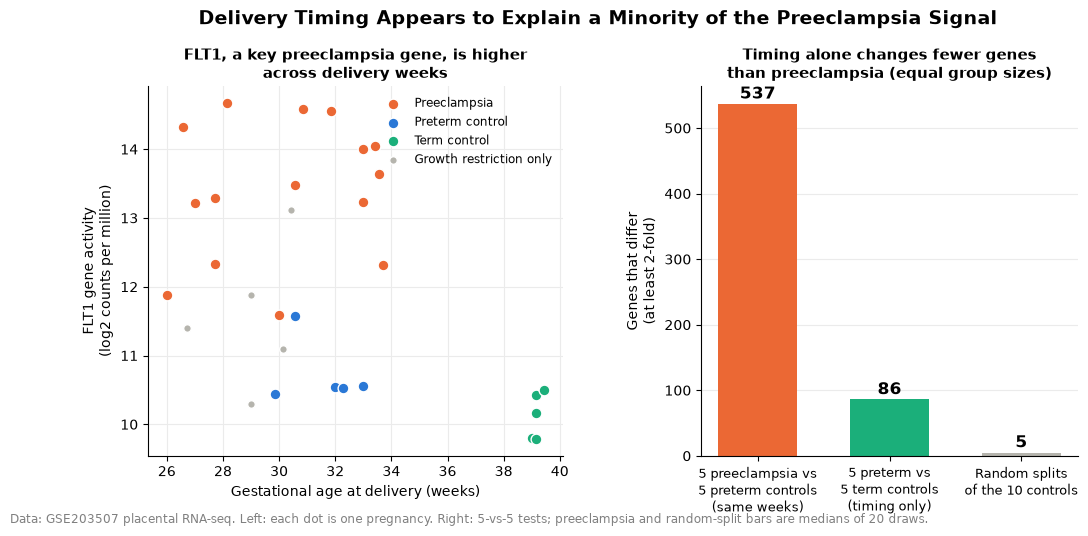

In [18]:
# Headline visual for a general audience
disease_med = int(np.median([d[1.0] for d in disease_draws]))
noise_med = int(np.median([d[1.0] for d in noise_draws]))
n_time = timing_actual[1.0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.35})
gene_vs_week(axes[0], "FLT1", legend=True)
axes[0].set_ylabel("FLT1 gene activity\n(log2 counts per million)")
axes[0].set_title("FLT1, a key preeclampsia gene, is higher\nacross delivery weeks", fontsize=11)
bars = [("5 preeclampsia vs\n5 preterm controls\n(same weeks)", disease_med, COLORS["PE"]),
        ("5 preterm vs\n5 term controls\n(timing only)", n_time, COLORS["term_control"]),
        ("Random splits\nof the 10 controls", noise_med, "#b5b4ad")]
for i, (lab, v, c) in enumerate(bars):
    axes[1].bar(i, v, color=c, width=0.6)
    axes[1].text(i, v + 8, str(v), ha="center", fontsize=12, fontweight="bold")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels([b[0] for b in bars], fontsize=9.5)
axes[1].set_ylabel("Genes that differ\n(at least 2-fold)")
axes[1].grid(axis="x", visible=False)
axes[1].set_title("Timing alone changes fewer genes\nthan preeclampsia (equal group sizes)", fontsize=11)
fig.suptitle("Delivery Timing Appears to Explain a Minority of the Preeclampsia Signal", fontsize=14, fontweight="bold", y=1.04)
fig.text(0.01, -0.03, "Data: GSE203507 placental RNA-seq. Left: each dot is one pregnancy. Right: 5-vs-5 tests; preeclampsia and random-split bars are "
         "medians of 20 draws.", fontsize=8.5, color="gray")
plt.savefig(RESULTS_DIR / "headline.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Robustness Checks

We reran the main comparison (PE vs preterm controls) three ways. Each targets something other than timing that differs between the groups:

- **Growth restriction:** 7 of the 15 cases also have growth restriction (FGR), and no preterm control does. We add `fgr_status` as a covariate.
- **Fetal sex:** placental gene activity differs by the baby's sex. We add `fetal_sex` as a covariate.
- **Remaining timing gap:** cases were delivered about 1.3 weeks earlier than preterm controls on average. We add delivery week as a covariate.

For each, we ask what share of our main genes still pass in the same direction.

In [19]:
main = res["PE vs preterm controls"]
main_hits = passing_genes(main).index
pt = metadata.loc[pe_ids + pre_ids, ["q6_group", "fgr_status", "fetal_sex", "ga_delivery_weeks"]]

def check(r):
    same = (r.loc[main_hits, "padj"] < PADJ_CUTOFF) & (np.sign(r.loc[main_hits, "log2FoldChange"]) == np.sign(main.loc[main_hits, "log2FoldChange"]))
    return {"genes passing": len(passing_genes(r)),
            "main genes still significant, same direction": f"{same.mean():.0%}",
            "fold-change agreement (correlation)": round(r.loc[main_hits, "log2FoldChange"].corr(main.loc[main_hits, "log2FoldChange"]), 2)}

rows = {}
for name, design in [("no covariate (baseline refit)", "~q6_group"),
                     ("+ growth restriction", "~fgr_status + q6_group"),
                     ("+ fetal sex", "~fetal_sex + q6_group"),
                     ("+ delivery week", "~ga_delivery_weeks + q6_group")]:
    r = test_contrast(fit_deseq(counts_f[pt.index], pt, design), ["q6_group", "PE", "preterm_control"])
    rows[name] = check(r)
robust = pd.DataFrame(rows).T
robust.to_csv(RESULTS_DIR / "robustness_checks.csv")
print(f"Main comparison: {len(main_hits)} genes")
display(robust)

Main comparison: 522 genes


,genes passing,"main genes still significant, same direction",fold-change agreement (correlation)
no covariate (baseline refit),472,89%,1.0
+ growth restriction,293,53%,0.99
+ fetal sex,426,78%,1.0
+ delivery week,529,87%,0.99


In [20]:
drop = ["S01_VT", "S12_VT"]
keep = [s for s in pt.index if s not in drop]
r = test_contrast(fit_deseq(counts_f[keep], pt.loc[keep], "~q6_group"), ["q6_group", "PE", "preterm_control"])
robust.loc["drop S01 and S12"] = pd.Series(check(r))
robust.to_csv(RESULTS_DIR / "robustness_checks.csv")
display(robust)

,genes passing,"main genes still significant, same direction",fold-change agreement (correlation)
no covariate (baseline refit),472,89%,1.0
+ growth restriction,293,53%,0.99
+ fetal sex,426,78%,1.0
+ delivery week,529,87%,0.99
drop S01 and S12,453,85%,1.0


**What this shows.** Our main result holds up. In every check the fold changes agree almost perfectly with the main analysis (correlation 0.99 to 1.0), so the *size and direction* of the differences do not depend on these factors.

- Adjusting for the remaining 1.3-week timing gap keeps 87% of the main genes significant. This is one more sign that timing matters little.
- Adjusting for fetal sex keeps 78%.
- Adjusting for growth restriction keeps only 53%. That is mostly lost power, not lost signal: growth restriction occurs only within the preeclampsia group here, so the model must estimate the preeclampsia effect from the 8 cases without it. The effect sizes stay the same (correlation 0.99).

---
## Our Answer

**Delivery timing explains only a minority of the difference between early-onset preeclampsia and control placentas in this dataset.**

- Comparing against controls delivered in the same weeks does not change the number of genes that differ (532 against term controls, 532 against preterm controls). The two lists only partly overlap (240 genes shared), so the exact genes are sensitive to which controls are used.
- Timing has a real but smaller effect. At equal group sizes (5 vs 5), preterm and term controls, delivered about 8 weeks apart, differ in 86 genes. That is clearly more than random splits of the controls (0 to 17) but about six times fewer than preeclampsia vs preterm controls (median 537 over 20 draws, range 232 to 763).
- About half (53%) of the differences against term controls hold up against same-time controls. About a quarter (28%) look driven by timing, and 18% are unclear. For the typical gene, timing accounts for about 30% of the difference.
- Core preeclampsia genes (FLT1, ENG, LEP, PAPPA2) are raised regardless of when delivery happened.
- The main comparison holds up after adjusting for growth restriction, fetal sex or delivery week, and after dropping S01 and S12. The fold changes agree closely in every check (correlation 0.99 to 1.0), although adjusting for growth restriction leaves only 52% of genes significant because it costs power.

**Limitations.**

- Our preterm controls are spontaneous preterm births, which often involve inflammation. They are the best comparison available, since healthy pregnancies are not delivered early, but they are not a healthy 31-week placenta.
- There are only 5 controls of each type.
- The random splits mix preterm and term controls, so they are a rough noise baseline that still contains some timing signal.
- Bulk tissue mixes many cell types, so we cannot tell whether genes change inside cells or because the cell mix changes.
- All cases are early onset, so the answer may differ for late-onset preeclampsia.
- All of this is association, not cause.

**Next steps.**

- Repeat the timing comparison inside single cell types, using the pseudobulk extension (early vs late control donors).
- Check FLT1, ENG, LEP and PAPPA2 against preterm controls in an independent cohort whose preterm deliveries were medically indicated rather than spontaneous.

Go to [Step 4: Submit](../4-submit.md).